# Cholec80 — SF-TMN with an ASFormer backbone

This is an **independent, paper-faithful reimplementation** of SF-TMN for a
controlled comparison with the project's existing temporal models. It is not
the authors' official code: no official SF-TMN repository was located.

Primary references:

- [SF-TMN paper](https://arxiv.org/abs/2306.08859)
- [Official ASFormer repository (MIT)](https://github.com/ChinaYi/ASFormer)
- [ASFormer paper](https://arxiv.org/abs/2110.08568)

## What is reproduced

- frame-level **Slow Path** and max-pooled segment-level **Fast Path**;
- 32-frame (32-second at 1 FPS) Fast-Path segments;
- ASFormer-style dilated temporal convolution + sliding local attention;
- one temporal modeling stage and three refinement stages per path;
- learned fusion of Slow features and upsampled Fast features;
- combined-output supervision with cross-entropy + truncated temporal MSE;
- 10 layers, 64 feature maps, Adam at 1e-4, batch size 1, up to 200 epochs.

## Important comparison caveat

The SF-TMN paper trained on videos 1-40 and tested on 41-80. This notebook uses
**1-32 train / 33-40 validation / 41-80 test**, matching the controlled protocol
used in Alessio's earlier benchmark. Therefore its result is scientifically
comparable to that benchmark, but is not a direct reproduction of the paper's
40/40 number. The paper's 94.72% is pooled accuracy; 95.43% is mean per-video
accuracy. This notebook reports both aggregations explicitly.



In [17]:
import gc
import json
import math
import random
import time
import warnings
import zipfile
from copy import deepcopy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    jaccard_score,
    precision_score,
    recall_score,
)
from torch.utils.checkpoint import checkpoint

warnings.filterwarnings("ignore")

# --------------------------- experiment configuration ---------------------------
SEED = 42                    # one fixed seed; no multi-seed sweep
FEATURE_SOURCE = "finetuned"  # "teammates", "finetuned", or "original"

TRAIN_IDS = list(range(1, 33))
VAL_IDS = list(range(33, 41))
TEST_IDS = list(range(41, 81))
NUM_CLASSES, FEATURE_DIM, FPS = 7, 2048, 1
PHASE_NAMES = [
    "Preparation", "CalotTriangleDissection", "ClippingCutting",
    "GallbladderDissection", "GallbladderPackaging",
    "CleaningCoagulation", "GallbladderRetraction",
]

# Paper configuration. Early stopping/checkpoint selection uses validation only.
MAX_EPOCHS, PATIENCE = 200, 25
LEARNING_RATE, WEIGHT_DECAY = 1e-4, 1e-5
NUM_LAYERS, NUM_MAPS, NUM_REFINEMENTS = 10, 64, 3
SEGMENT_LENGTH = 32
ATTENTION_Q_REDUCTION, ATTENTION_V_REDUCTION = 2, 2
CHANNEL_MASK_RATE = 0.30
SMOOTHING_WEIGHT, SMOOTHING_CLIP = 0.15, 16.0
USE_CLASS_WEIGHTS = False    # paper uses ordinary cross-entropy
USE_AMP = True
USE_GRADIENT_CHECKPOINTING = True  # recommended for 8 GB GPUs
GRADIENT_CLIP = 5.0
NORMALIZE_FEATURES = False
USE_VITERBI_CANDIDATE = True # fitted on train, selected on validation

RUN_NAME = f"sftmn_asformer_{FEATURE_SOURCE}"
RESULTS_DIR = Path("/kaggle/working") / RUN_NAME
CHECKPOINT_DIR = RESULTS_DIR / "checkpoints"
PREDICTION_DIR = RESULTS_DIR / "predictions"
for directory in (RESULTS_DIR, CHECKPOINT_DIR, PREDICTION_DIR):
    directory.mkdir(parents=True, exist_ok=True)

FEATURE_SOURCES = {
    "teammates": {
        "description": "Giorgia/Marta 1 FPS frames -> ImageNet ResNet50 features",
        "paths": [
            "/kaggle/input/datasets/christiancorvino/features-teammates/features",
            "/kaggle/input/features-teammates/features",
        ],
    },
    "finetuned": {
        "description": "Christian fine-tuned ResNet50 features from original videos",
        "paths": [
            "/kaggle/input/datasets/christiancorvino/features-resnet50finetuned/features_finetuned",
            "/kaggle/input/features-resnet50finetuned/features_finetuned",
            "/kaggle/input/notebooks/christiancorvino/cholec80-resnet50-finetuning/features_finetuned",
        ],
    },
    "original": {
        "description": "Christian initial direct-from-video ImageNet ResNet50 features",
        "paths": [
            "/kaggle/input/datasets/christiancorvino/cholec80-features/features",
            "/kaggle/input/cholec80-features/features",
        ],
    },
}

if FEATURE_SOURCE not in FEATURE_SOURCES:
    raise ValueError(f"Unknown FEATURE_SOURCE={FEATURE_SOURCE!r}")

FEATURE_DIR = next(
    (Path(p) for p in FEATURE_SOURCES[FEATURE_SOURCE]["paths"] if Path(p).is_dir()),
    None,
)
if FEATURE_DIR is None:
    expected = "\n".join(FEATURE_SOURCES[FEATURE_SOURCE]["paths"])
    raise FileNotFoundError(
        f"Attach the Kaggle dataset for FEATURE_SOURCE={FEATURE_SOURCE!r}. "
        f"Expected one of:\n{expected}"
    )

if not torch.cuda.is_available():
    raise RuntimeError("Enable a Kaggle GPU accelerator before running this notebook.")
if torch.cuda.get_device_capability(0) < (7, 0):
    gpu = torch.cuda.get_device_name(0)
    capability = ".".join(map(str, torch.cuda.get_device_capability(0)))
    raise RuntimeError(
        f"GPU {gpu} has CUDA capability {capability}; use a T4/A4000 or newer GPU."
    )

DEVICE = torch.device("cuda")
USE_AMP = bool(USE_AMP and DEVICE.type == "cuda")
torch.set_float32_matmul_precision("high")

def reset_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

reset_seed()
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("GPU:", torch.cuda.get_device_name(0))
print("CUDA capability:", torch.cuda.get_device_capability(0))
print("PyTorch / CUDA:", torch.__version__, "/", torch.version.cuda)
print("Run name:", RUN_NAME)
print("Feature lineage:", FEATURE_SOURCES[FEATURE_SOURCE]["description"])
print("Feature directory:", FEATURE_DIR)
print("Split: 32 train / 8 validation / 40 test")



GPU: Tesla T4
CUDA capability: (7, 5)
PyTorch / CUDA: 2.10.0+cu128 / 12.8
Run name: sftmn_asformer_finetuned
Feature lineage: Christian fine-tuned ResNet50 features from original videos
Feature directory: /kaggle/input/datasets/christiancorvino/features-resnet50finetuned/features_finetuned
Split: 32 train / 8 validation / 40 test


## 1. Existing visual preprocessing and executed temporal preprocessing

The upstream visual preprocessing is already complete:

```text
video + phase annotation -> 1 FPS -> ResNet50 -> 2048-D feature per second
```

Re-extracting frames or features here would waste compute and change the input to
the temporal comparison. This section instead verifies every feature/label pair,
records its provenance, and optionally computes normalization statistics from the
training set only. Test arrays are not loaded into RAM until final evaluation.



In [18]:
def feature_paths(video_id):
    return (
        FEATURE_DIR / f"video{video_id:02d}_features.npy",
        FEATURE_DIR / f"video{video_id:02d}_labels.npy",
    )

inventory = []
for video_id in range(1, 81):
    feature_path, label_path = feature_paths(video_id)
    if not feature_path.exists() or not label_path.exists():
        raise FileNotFoundError(f"Missing feature/label pair for video {video_id:02d}")
    features = np.load(feature_path, mmap_mode="r")
    labels = np.load(label_path, mmap_mode="r")
    if features.ndim != 2 or features.shape[1] != FEATURE_DIM:
        raise ValueError(f"video{video_id:02d}: invalid feature shape {features.shape}")
    if labels.ndim != 1 or len(features) != len(labels):
        raise ValueError(f"video{video_id:02d}: unaligned shapes {features.shape}, {labels.shape}")
    if not np.isfinite(features).all():
        raise ValueError(f"video{video_id:02d}: NaN or infinity in features")
    if labels.min() < 0 or labels.max() >= NUM_CLASSES:
        raise ValueError(f"video{video_id:02d}: invalid phase IDs")
    inventory.append({
        "video": video_id,
        "samples": len(labels),
        "minutes": len(labels) / 60,
        "feature_dim": features.shape[1],
        "phases_present": len(np.unique(labels)),
    })

inventory = pd.DataFrame(inventory)
display(inventory)
display(inventory.describe())
inventory.to_csv(RESULTS_DIR / "feature_inventory.csv", index=False)

def calculate_train_stats(video_ids):
    total = 0
    sum_x = np.zeros(FEATURE_DIM, dtype=np.float64)
    sum_x2 = np.zeros(FEATURE_DIM, dtype=np.float64)
    for video_id in video_ids:
        x = np.asarray(np.load(feature_paths(video_id)[0], mmap_mode="r"), dtype=np.float64)
        total += len(x)
        sum_x += x.sum(axis=0)
        sum_x2 += np.square(x).sum(axis=0)
    mean = sum_x / total
    std = np.sqrt(np.maximum(sum_x2 / total - np.square(mean), 1e-8))
    return mean.astype(np.float32), std.astype(np.float32)

FEATURE_MEAN, FEATURE_STD = (
    calculate_train_stats(TRAIN_IDS) if NORMALIZE_FEATURES else (None, None)
)

class FeatureSequenceDataset:
    def __init__(self, video_ids):
        self.video_ids = list(video_ids)
        self.data = []
        for video_id in self.video_ids:
            x = np.load(feature_paths(video_id)[0]).astype(np.float32)
            y = np.load(feature_paths(video_id)[1]).astype(np.int64)
            if NORMALIZE_FEATURES:
                x = (x - FEATURE_MEAN) / FEATURE_STD
            self.data.append({
                "video_id": video_id,
                "features": torch.from_numpy(x),
                "labels": torch.from_numpy(y),
            })

    def __len__(self):
        return len(self.data)

train_ds = FeatureSequenceDataset(TRAIN_IDS)
val_ds = FeatureSequenceDataset(VAL_IDS)

train_labels = np.concatenate([item["labels"].numpy() for item in train_ds.data])
class_counts = np.bincount(train_labels, minlength=NUM_CLASSES)
balanced_weights = len(train_labels) / (NUM_CLASSES * np.maximum(class_counts, 1))
class_weights = (
    torch.tensor(balanced_weights, dtype=torch.float32, device=DEVICE)
    if USE_CLASS_WEIGHTS else None
)
print("Training samples:", len(train_labels))
print("Class counts:", class_counts.tolist())
print("Cross-entropy:", "class-weighted" if USE_CLASS_WEIGHTS else "unweighted (paper setting)")



,video,samples,minutes,feature_dim,phases_present
0,1,1734,28.900000,2048,7
1,2,2840,47.333333,2048,7
2,3,5829,97.150000,2048,7
3,4,1523,25.383333,2048,7
4,5,2345,39.083333,2048,7
...,...,...,...,...,...
75,76,2650,44.166667,2048,7
76,77,2503,41.716667,2048,7
77,78,740,12.333333,2048,7
78,79,3415,56.916667,2048,7


,video,samples,minutes,feature_dim,phases_present
count,80.0000,80.000000,80.000000,80.0,80.000000
mean,40.5000,2307.225000,38.453750,2048.0,6.812500
std,23.2379,1025.529057,17.092151,0.0,0.392775
min,1.0000,740.000000,12.333333,2048.0,6.000000
25%,20.7500,1645.000000,27.416667,2048.0,7.000000
50%,40.5000,2096.000000,34.933333,2048.0,7.000000
75%,60.2500,2861.500000,47.691667,2048.0,7.000000
max,80.0000,5994.000000,99.900000,2048.0,7.000000


Training samples: 71032
Class counts: [3104, 29730, 6139, 20046, 3084, 5979, 2950]
Cross-entropy: unweighted (paper setting)


## 2. Metrics — framewise, segmental, pooled, and video-by-video

Each video is evaluated independently before aggregation; no filter or segment
operation can cross a video boundary. Values are stored on the [0, 1] scale.



In [19]:
def extract_segments(sequence):
    sequence = np.asarray(sequence, dtype=np.int64)
    if len(sequence) == 0:
        return np.array([], int), np.array([], int), np.array([], int)
    change = np.r_[True, sequence[1:] != sequence[:-1]]
    starts = np.flatnonzero(change)
    ends = np.r_[starts[1:], len(sequence)]
    return sequence[starts], starts, ends

def normalized_edit_score(target, prediction):
    target_segments = extract_segments(target)[0].tolist()
    pred_segments = extract_segments(prediction)[0].tolist()
    previous = list(range(len(pred_segments) + 1))
    for i, target_label in enumerate(target_segments, 1):
        current = [i]
        for j, pred_label in enumerate(pred_segments, 1):
            current.append(min(
                current[-1] + 1,
                previous[j] + 1,
                previous[j - 1] + int(target_label != pred_label),
            ))
        previous = current
    distance = previous[-1]
    return 1.0 - distance / max(len(target_segments), len(pred_segments), 1)

def segmental_f1_counts(target, prediction, overlap):
    gt_labels, gt_starts, gt_ends = extract_segments(target)
    pr_labels, pr_starts, pr_ends = extract_segments(prediction)
    matched = np.zeros(len(gt_labels), dtype=bool)
    tp = fp = 0
    for label, start, end in zip(pr_labels, pr_starts, pr_ends):
        intersection = np.minimum(end, gt_ends) - np.maximum(start, gt_starts)
        union = np.maximum(end, gt_ends) - np.minimum(start, gt_starts)
        iou = (intersection / np.maximum(union, 1)) * (gt_labels == label)
        best = int(np.argmax(iou)) if len(iou) else -1
        if best >= 0 and iou[best] >= overlap and not matched[best]:
            tp += 1
            matched[best] = True
        else:
            fp += 1
    return tp, fp, int((~matched).sum())

def frame_metrics(target, prediction):
    labels = np.arange(NUM_CLASSES)
    return {
        "accuracy": accuracy_score(target, prediction),
        "precision_macro": precision_score(
            target, prediction, labels=labels, average="macro", zero_division=0),
        "recall_macro": recall_score(
            target, prediction, labels=labels, average="macro", zero_division=0),
        "f1_macro": f1_score(
            target, prediction, labels=labels, average="macro", zero_division=0),
        "jaccard_macro": jaccard_score(
            target, prediction, labels=labels, average="macro", zero_division=0),
    }

def evaluate_sequences(results, prediction_key="preds"):
    all_target, all_prediction, edits = [], [], []
    counts = {0.10: [0, 0, 0], 0.25: [0, 0, 0], 0.50: [0, 0, 0]}
    per_video_frames = []
    for video_id in sorted(results):
        target = np.asarray(results[video_id]["labels"])
        prediction = np.asarray(results[video_id][prediction_key])
        all_target.append(target)
        all_prediction.append(prediction)
        edits.append(normalized_edit_score(target, prediction))
        per_video_frames.append(frame_metrics(target, prediction))
        for overlap in counts:
            values = segmental_f1_counts(target, prediction, overlap)
            counts[overlap] = [a + b for a, b in zip(counts[overlap], values)]

    target = np.concatenate(all_target)
    prediction = np.concatenate(all_prediction)
    metrics = frame_metrics(target, prediction)
    metrics["edit"] = float(np.mean(edits))
    for overlap, (tp, fp, fn) in counts.items():
        precision = tp / max(tp + fp, 1)
        recall = tp / max(tp + fn, 1)
        metrics[f"f1_at_{int(overlap * 100)}"] = (
            2 * precision * recall / max(precision + recall, 1e-12)
        )
    metrics["f1_segmental_avg"] = np.mean([
        metrics["f1_at_10"], metrics["f1_at_25"], metrics["f1_at_50"]
    ])

    # The SF-TMN paper's Table 6 uses mean +/- std over videos.
    for metric_name in ("accuracy", "precision_macro", "recall_macro", "jaccard_macro"):
        values = np.array([row[metric_name] for row in per_video_frames])
        metrics[f"video_mean_{metric_name}"] = float(values.mean())
        metrics[f"video_std_{metric_name}"] = float(values.std(ddof=0))
    return metrics

def per_video_metrics(results, prediction_key="preds"):
    rows = []
    for video_id in sorted(results):
        target = results[video_id]["labels"]
        prediction = results[video_id][prediction_key]
        frame = frame_metrics(target, prediction)
        counts = {}
        for overlap in (0.10, 0.25, 0.50):
            tp, fp, fn = segmental_f1_counts(target, prediction, overlap)
            p = tp / max(tp + fp, 1)
            r = tp / max(tp + fn, 1)
            counts[f"f1_at_{int(overlap * 100)}"] = 2 * p * r / max(p + r, 1e-12)
        rows.append({
            "video": video_id,
            **frame,
            "edit": normalized_edit_score(target, prediction),
            **counts,
            "f1_segmental_avg": np.mean(list(counts.values())),
        })
    return pd.DataFrame(rows)



## 3. ASFormer building blocks

The implementation follows the official ASFormer structure: each block combines
a dilated temporal convolution with single-head sliding-window attention. Query
and key come from the current decoder representation; decoder values come from
the previous stage's features. Attention window size grows as 1, 2, 4, ..., 512.



In [20]:
def decoder_attention_scale(index, decay=3.0):
    return math.exp(-decay * index)

class SlidingWindowAttention(nn.Module):
    def __init__(self, channels, block_length, decoder=False):
        super().__init__()
        self.channels = channels
        self.block_length = block_length
        self.decoder = decoder
        qk_channels = channels // ATTENTION_Q_REDUCTION
        value_channels = channels // ATTENTION_V_REDUCTION
        self.query = nn.Conv1d(channels, qk_channels, 1)
        self.key = nn.Conv1d(channels, qk_channels, 1)
        self.value = nn.Conv1d(channels, value_channels, 1)
        self.output = nn.Conv1d(value_channels, channels, 1)

        half = block_length // 2
        context_length = block_length + 2 * half
        window = torch.zeros(1, block_length, context_length)
        for index in range(block_length):
            window[:, index, index:index + block_length] = 1.0
        self.register_buffer("window_mask", window, persistent=False)

    def forward(self, current, context, mask):
        query = self.query(current)
        key = self.key(current)
        value_source = context if self.decoder else current
        if value_source is None:
            raise ValueError("Decoder attention requires previous-stage features")
        value = self.value(value_source)

        batch, qk_channels, length = query.shape
        value_channels = value.shape[1]
        block = self.block_length
        half = block // 2
        context_length = block + 2 * half
        blocks = math.ceil(length / block)
        padded_length = blocks * block
        right_pad = padded_length - length

        query = F.pad(query, (0, right_pad))
        key = F.pad(key, (0, right_pad))
        value = F.pad(value, (0, right_pad))
        valid = F.pad(mask[:, :1], (0, right_pad))

        query_blocks = (
            query.view(batch, qk_channels, blocks, block)
            .permute(0, 2, 1, 3)
            .reshape(batch * blocks, qk_channels, block)
        )
        key = F.pad(key, (half, half))
        value = F.pad(value, (half, half))
        valid = F.pad(valid, (half, half))
        key_windows = (
            key.unfold(-1, context_length, block)
            .permute(0, 2, 1, 3)
            .reshape(batch * blocks, qk_channels, context_length)
        )
        value_windows = (
            value.unfold(-1, context_length, block)
            .permute(0, 2, 1, 3)
            .reshape(batch * blocks, value_channels, context_length)
        )
        valid_windows = (
            valid.unfold(-1, context_length, block)
            .permute(0, 2, 1, 3)
            .reshape(batch * blocks, 1, context_length)
        )

        energy = torch.bmm(query_blocks.transpose(1, 2), key_windows)
        energy = energy / math.sqrt(qk_channels)
        attention_mask = valid_windows * self.window_mask.to(dtype=valid_windows.dtype)
        attention = torch.softmax(energy + torch.log(attention_mask + 1e-6), dim=-1)
        attention = attention * attention_mask
        attended = torch.bmm(value_windows, attention.transpose(1, 2))
        attended = F.relu(attended)
        attended = (
            attended.view(batch, blocks, value_channels, block)
            .permute(0, 2, 1, 3)
            .reshape(batch, value_channels, padded_length)[:, :, :length]
        )
        return self.output(attended) * mask[:, :1]

class ASFormerBlock(nn.Module):
    def __init__(self, dilation, decoder=False, attention_scale=1.0):
        super().__init__()
        self.decoder = decoder
        self.temporal_conv = nn.Conv1d(
            NUM_MAPS, NUM_MAPS, kernel_size=3, padding=dilation, dilation=dilation
        )
        self.norm = nn.InstanceNorm1d(NUM_MAPS, track_running_stats=False)
        self.attention = SlidingWindowAttention(NUM_MAPS, dilation, decoder=decoder)
        self.mix = nn.Conv1d(NUM_MAPS, NUM_MAPS, 1)
        self.dropout = nn.Dropout(0.5)
        self.attention_scale = attention_scale

    def forward(self, x, context, mask):
        out = F.relu(self.temporal_conv(x))
        attended = self.attention(self.norm(out), context, mask)
        out = out + self.attention_scale * attended
        out = self.dropout(self.mix(out))
        return (x + out) * mask[:, :1]

class ASFormerStage(nn.Module):
    def __init__(self, input_dim, decoder=False, decoder_index=0, channel_mask_rate=0.0):
        super().__init__()
        self.decoder = decoder
        self.channel_mask_rate = channel_mask_rate
        self.channel_dropout = nn.Dropout1d(channel_mask_rate)
        self.input_projection = nn.Conv1d(input_dim, NUM_MAPS, 1)
        attention_scale = decoder_attention_scale(decoder_index) if decoder else 1.0
        self.layers = nn.ModuleList([
            ASFormerBlock(2 ** index, decoder=decoder, attention_scale=attention_scale)
            for index in range(NUM_LAYERS)
        ])
        self.classifier = nn.Conv1d(NUM_MAPS, NUM_CLASSES, 1)

    def _run_layer(self, layer, feature, context, mask):
        if self.training and USE_GRADIENT_CHECKPOINTING:
            if self.decoder:
                return checkpoint(layer, feature, context, mask, use_reentrant=False)
            return checkpoint(
                lambda current, valid: layer(current, None, valid),
                feature,
                mask,
                use_reentrant=False,
            )
        return layer(feature, context, mask)

    def forward(self, x, mask, context=None):
        if self.channel_mask_rate > 0 and not self.decoder:
            x = self.channel_dropout(x)
        feature = self.input_projection(x)
        for layer in self.layers:
            feature = self._run_layer(layer, feature, context, mask)
        logits = self.classifier(feature) * mask[:, :1]
        return logits, feature



## 4. SF-TMN: Slow Path + Fast Path + Slow-Path refinement

At each stage, Fast features are upsampled to frame resolution and fused with
Slow features using learned normalized weights. Following the best design in the
SF-TMN paper (Figure 3a), the next Slow refinement consumes the **combined**
prediction and feature, while the Fast refinement remains on its own path.



In [21]:
class SFTMNASFormer(nn.Module):
    def __init__(self):
        super().__init__()
        self.slow_encoder = ASFormerStage(
            FEATURE_DIM, decoder=False, channel_mask_rate=CHANNEL_MASK_RATE
        )
        self.fast_encoder = ASFormerStage(
            FEATURE_DIM, decoder=False, channel_mask_rate=CHANNEL_MASK_RATE
        )
        self.slow_decoders = nn.ModuleList([
            ASFormerStage(NUM_CLASSES, decoder=True, decoder_index=index)
            for index in range(NUM_REFINEMENTS)
        ])
        self.fast_decoders = nn.ModuleList([
            ASFormerStage(NUM_CLASSES, decoder=True, decoder_index=index)
            for index in range(NUM_REFINEMENTS)
        ])
        self.fusion_logits = nn.Parameter(torch.zeros(NUM_REFINEMENTS + 1, 2))
        self.fusion_heads = nn.ModuleList([
            nn.Conv1d(NUM_MAPS, NUM_CLASSES, 1)
            for _ in range(NUM_REFINEMENTS + 1)
        ])

    def fuse(self, slow_feature, fast_feature, stage_index):
        upsampled_fast = F.interpolate(
            fast_feature, size=slow_feature.shape[-1], mode="nearest"
        )
        weights = torch.softmax(self.fusion_logits[stage_index], dim=0)
        return weights[0] * slow_feature + weights[1] * upsampled_fast

    def forward(self, x):
        # x: [batch=1, 2048, time]
        length = x.shape[-1]
        slow_mask = x.new_ones((x.shape[0], 1, length))
        fast_x = F.max_pool1d(
            x, kernel_size=SEGMENT_LENGTH, stride=SEGMENT_LENGTH, ceil_mode=True
        )
        fast_mask = x.new_ones((x.shape[0], 1, fast_x.shape[-1]))

        slow_logits, slow_feature = self.slow_encoder(x, slow_mask)
        fast_logits, fast_feature = self.fast_encoder(fast_x, fast_mask)
        combined_feature = self.fuse(slow_feature, fast_feature, stage_index=0)
        combined_logits = self.fusion_heads[0](combined_feature) * slow_mask
        outputs = [combined_logits]

        for index, (slow_decoder, fast_decoder) in enumerate(
            zip(self.slow_decoders, self.fast_decoders), start=1
        ):
            fast_input = F.softmax(fast_logits, dim=1) * fast_mask
            fast_logits, fast_feature = fast_decoder(
                fast_input, fast_mask, context=fast_feature * fast_mask
            )

            slow_input = F.softmax(combined_logits, dim=1) * slow_mask
            slow_logits, slow_feature = slow_decoder(
                slow_input, slow_mask, context=combined_feature * slow_mask
            )

            combined_feature = self.fuse(slow_feature, fast_feature, stage_index=index)
            combined_logits = self.fusion_heads[index](combined_feature) * slow_mask
            outputs.append(combined_logits)
        return outputs

model = SFTMNASFormer().to(DEVICE)
parameter_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"SF-TMN(ASFormer): {parameter_count:,} trainable parameters")

# Shape and backward-pass smoke test before hours of training.
reset_seed()
model.train()
smoke_x = torch.randn(1, FEATURE_DIM, 257, device=DEVICE)
with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
    smoke_outputs = model(smoke_x)
    smoke_loss = sum(output.float().square().mean() for output in smoke_outputs)
assert len(smoke_outputs) == NUM_REFINEMENTS + 1
assert all(output.shape == (1, NUM_CLASSES, 257) for output in smoke_outputs)
smoke_loss.backward()
print("Smoke test passed:", [tuple(output.shape) for output in smoke_outputs])
del model, smoke_x, smoke_outputs, smoke_loss
gc.collect()
torch.cuda.empty_cache()



SF-TMN(ASFormer): 2,259,932 trainable parameters
Smoke test passed: [(1, 7, 257), (1, 7, 257), (1, 7, 257), (1, 7, 257)]


## 5. Multi-stage loss, training, and validation-only selection

Every combined stage is supervised. The smoothing term compares adjacent
log-probabilities and stops gradients through the previous time point, following
ASFormer. Best checkpoint = maximum validation mean F1@{10,25,50}. Test is not
used for checkpoint or post-processing decisions.




===== Training SF-TMN(ASFormer) =====
epoch=001 train=6.4660 val=4.8158 Acc=0.467 J=0.067 Edit=0.223 F1avg=0.192 stale=0/25
epoch=002 train=4.6452 val=3.4943 Acc=0.664 J=0.172 Edit=0.298 F1avg=0.370 stale=0/25
epoch=003 train=3.5578 val=2.5630 Acc=0.715 J=0.197 Edit=0.298 F1avg=0.429 stale=0/25
epoch=004 train=2.5721 val=1.8727 Acc=0.702 J=0.194 Edit=0.298 F1avg=0.429 stale=1/25
epoch=005 train=1.8943 val=1.4367 Acc=0.863 J=0.516 Edit=0.664 F1avg=0.717 stale=0/25
epoch=006 train=1.4881 val=1.3051 Acc=0.876 J=0.579 Edit=0.756 F1avg=0.752 stale=0/25
epoch=007 train=1.2396 val=1.1545 Acc=0.907 J=0.719 Edit=0.897 F1avg=0.862 stale=0/25
epoch=008 train=1.0749 val=1.1099 Acc=0.909 J=0.712 Edit=0.871 F1avg=0.835 stale=1/25
epoch=009 train=0.9545 val=0.9401 Acc=0.925 J=0.773 Edit=0.830 F1avg=0.881 stale=0/25
epoch=010 train=0.8309 val=0.8740 Acc=0.936 J=0.806 Edit=0.897 F1avg=0.920 stale=0/25
epoch=011 train=0.7449 val=0.7865 Acc=0.946 J=0.825 Edit=0.911 F1avg=0.935 stale=0/25
epoch=012 train

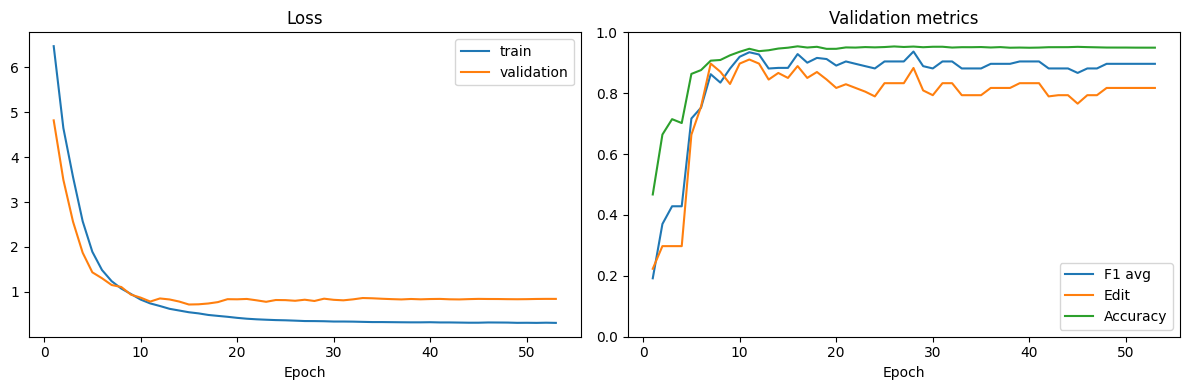

In [22]:
criterion = nn.CrossEntropyLoss(weight=class_weights)

def stage_loss(logits, labels):
    classification = criterion(logits, labels)
    log_probabilities = F.log_softmax(logits, dim=1)
    squared_change = F.mse_loss(
        log_probabilities[:, :, 1:],
        log_probabilities.detach()[:, :, :-1],
        reduction="none",
    )
    smoothing = torch.clamp(squared_change, min=0.0, max=SMOOTHING_CLIP).mean()
    return classification + SMOOTHING_WEIGHT * smoothing

def combined_loss(outputs, labels):
    return sum(stage_loss(logits, labels) for logits in outputs)

@torch.no_grad()
def predict_dataset(model, dataset):
    model.eval()
    results = {}
    start = time.perf_counter()
    for item in dataset.data:
        x = item["features"].T.unsqueeze(0).to(DEVICE, non_blocking=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(x)[-1].squeeze(0)
        log_probabilities = F.log_softmax(logits.float(), dim=0).T.cpu().numpy()
        results[item["video_id"]] = {
            "labels": item["labels"].numpy(),
            "preds": log_probabilities.argmax(axis=1),
            "log_probs": log_probabilities,
        }
    return results, time.perf_counter() - start

@torch.no_grad()
def validation_loss(model, dataset):
    model.eval()
    values = []
    for item in dataset.data:
        x = item["features"].T.unsqueeze(0).to(DEVICE, non_blocking=True)
        y = item["labels"].unsqueeze(0).to(DEVICE, non_blocking=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            values.append(combined_loss(model(x), y).item())
    return float(np.mean(values))

def train_model():
    reset_seed()
    model = SFTMNASFormer().to(DEVICE)
    optimizer = torch.optim.Adam(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=5, min_lr=1e-6
    )
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    history, best_state = [], None
    best_primary, stale = -np.inf, 0
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    training_start = time.perf_counter()

    print("\n===== Training SF-TMN(ASFormer) =====")
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        losses = []
        for index in np.random.permutation(len(train_ds.data)):
            item = train_ds.data[index]
            x = item["features"].T.unsqueeze(0).to(DEVICE, non_blocking=True)
            y = item["labels"].unsqueeze(0).to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                loss = combined_loss(model(x), y)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP)
            scaler.step(optimizer)
            scaler.update()
            losses.append(loss.item())

        val_results, _ = predict_dataset(model, val_ds)
        val_metrics = evaluate_sequences(val_results)
        val_loss = validation_loss(model, val_ds)
        scheduler.step(val_loss)
        primary = val_metrics["f1_segmental_avg"]
        history.append({
            "epoch": epoch,
            "train_loss": float(np.mean(losses)),
            "val_loss": val_loss,
            "val_accuracy": val_metrics["accuracy"],
            "val_f1_macro": val_metrics["f1_macro"],
            "val_jaccard_macro": val_metrics["jaccard_macro"],
            "val_edit": val_metrics["edit"],
            "val_f1_at_10": val_metrics["f1_at_10"],
            "val_f1_at_25": val_metrics["f1_at_25"],
            "val_f1_at_50": val_metrics["f1_at_50"],
            "val_f1_segmental_avg": primary,
            "lr": optimizer.param_groups[0]["lr"],
        })

        if primary > best_primary:
            best_primary = primary
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            torch.save(best_state, CHECKPOINT_DIR / "best_sftmn_asformer.pt")
            stale = 0
        else:
            stale += 1

        print(
            f"epoch={epoch:03d} train={np.mean(losses):.4f} val={val_loss:.4f} "
            f"Acc={val_metrics['accuracy']:.3f} J={val_metrics['jaccard_macro']:.3f} "
            f"Edit={val_metrics['edit']:.3f} F1avg={primary:.3f} "
            f"stale={stale}/{PATIENCE}"
        )
        if stale >= PATIENCE:
            print(f"Early stopping after {epoch} epochs")
            break

    if best_state is None:
        raise RuntimeError("Training ended without a valid checkpoint")
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), {
        "parameters": parameter_count,
        "training_seconds": time.perf_counter() - training_start,
        "peak_vram_mb": torch.cuda.max_memory_allocated() / (1024 ** 2),
        "best_val_f1_segmental_avg": best_primary,
    }

model, history, training_summary = train_model()
history.to_csv(RESULTS_DIR / "training_history.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["epoch"], history["train_loss"], label="train")
axes[0].plot(history["epoch"], history["val_loss"], label="validation")
axes[0].set(title="Loss", xlabel="Epoch")
axes[0].legend()
axes[1].plot(history["epoch"], history["val_f1_segmental_avg"], label="F1 avg")
axes[1].plot(history["epoch"], history["val_edit"], label="Edit")
axes[1].plot(history["epoch"], history["val_accuracy"], label="Accuracy")
axes[1].set(title="Validation metrics", xlabel="Epoch", ylim=(0, 1))
axes[1].legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "training_curves.png", dpi=160)
plt.show()



In [23]:
def training_transition_model(dataset):
    transitions = np.full((NUM_CLASSES, NUM_CLASSES), 1e-3, dtype=np.float64)
    starts = np.full(NUM_CLASSES, 1e-3, dtype=np.float64)
    for item in dataset.data:
        labels = item["labels"].numpy()
        starts[labels[0]] += 1
        for previous, current in zip(labels[:-1], labels[1:]):
            transitions[previous, current] += 1
    transitions /= transitions.sum(axis=1, keepdims=True)
    starts /= starts.sum()
    return np.log(transitions), np.log(starts)

TRANSITION_LOG, START_LOG = training_transition_model(train_ds)

def viterbi_decode(log_probabilities):
    length, classes = log_probabilities.shape
    score = np.full((length, classes), -np.inf, dtype=np.float64)
    back = np.zeros((length, classes), dtype=np.int64)
    score[0] = START_LOG + log_probabilities[0]
    for time_index in range(1, length):
        candidates = score[time_index - 1][:, None] + TRANSITION_LOG
        back[time_index] = candidates.argmax(axis=0)
        score[time_index] = candidates.max(axis=0) + log_probabilities[time_index]
    path = np.zeros(length, dtype=np.int64)
    path[-1] = score[-1].argmax()
    for time_index in range(length - 2, -1, -1):
        path[time_index] = back[time_index + 1, path[time_index + 1]]
    return path

def add_postprocessing(results):
    output = deepcopy(results)
    for item in output.values():
        item["viterbi"] = viterbi_decode(item["log_probs"])
    return output

validation_results, validation_inference_seconds = predict_dataset(model, val_ds)
validation_results = add_postprocessing(validation_results)
validation_rows = [{"postprocessing": "raw", **evaluate_sequences(validation_results, "preds")}]
if USE_VITERBI_CANDIDATE:
    validation_rows.append({
        "postprocessing": "viterbi",
        **evaluate_sequences(validation_results, "viterbi"),
    })
validation_table = pd.DataFrame(validation_rows).sort_values(
    ["f1_segmental_avg", "edit"], ascending=False
).reset_index(drop=True)
SELECTED_POSTPROCESSING = validation_table.iloc[0]["postprocessing"]
SELECTED_KEY = "preds" if SELECTED_POSTPROCESSING == "raw" else "viterbi"
validation_table.to_csv(RESULTS_DIR / "validation_postprocessing.csv", index=False)
display(validation_table)
print("Frozen validation decision:", SELECTED_POSTPROCESSING)

for video_id, values in validation_results.items():
    np.savez_compressed(
        PREDICTION_DIR / f"{RUN_NAME}_val_video{video_id:02d}.npz",
        labels=values["labels"],
        log_probs=values["log_probs"],
        raw=values["preds"],
        viterbi=values["viterbi"],
    )

del validation_results
gc.collect()
torch.cuda.empty_cache()



,postprocessing,accuracy,precision_macro,recall_macro,f1_macro,jaccard_macro,edit,f1_at_10,f1_at_25,f1_at_50,f1_segmental_avg,video_mean_accuracy,video_std_accuracy,video_mean_precision_macro,video_std_precision_macro,video_mean_recall_macro,video_std_recall_macro,video_mean_jaccard_macro,video_std_jaccard_macro
0,viterbi,0.954154,0.941116,0.932867,0.936052,0.881197,0.897321,0.945455,0.945455,0.945455,0.945455,0.947640,0.052255,0.870406,0.137862,0.869110,0.113536,0.814742,0.144475
1,raw,0.953239,0.939757,0.932588,0.935214,0.879816,0.882937,0.936937,0.936937,0.936937,0.936937,0.946579,0.051533,0.869113,0.136788,0.868794,0.113214,0.813110,0.142891


Frozen validation decision: viterbi


## 6. Final test — loaded and evaluated once

Architecture, checkpoint, and post-processing are now frozen. This is the first
section that loads videos 41-80 into RAM.



,0
model,SF-TMN(ASFormer)
feature_source,finetuned
feature_lineage,Christian fine-tuned ResNet50 features from or...
postprocessing,viterbi
parameters,2259932
training_minutes,19.41938
peak_vram_mb,335.847168
validation_inference_seconds,1.006449
test_inference_seconds,5.167224
accuracy,0.91621


,video,accuracy,precision_macro,recall_macro,f1_macro,jaccard_macro,edit,f1_at_10,f1_at_25,f1_at_50,f1_segmental_avg
0,41,0.913015,0.914146,0.855774,0.870641,0.783572,0.583333,0.736842,0.736842,0.526316,0.666667
1,42,0.966065,0.935648,0.924742,0.919382,0.861129,0.636364,0.777778,0.777778,0.666667,0.740741
2,43,0.888278,0.874862,0.845000,0.829557,0.731288,0.636364,0.777778,0.777778,0.555556,0.703704
3,44,0.993286,0.975821,0.985396,0.980001,0.961406,1.000000,1.000000,1.000000,1.000000,1.000000
4,45,0.982881,0.978842,0.945918,0.958612,0.924893,1.000000,1.000000,1.000000,1.000000,1.000000
5,46,0.979444,0.983025,0.949219,0.964007,0.932246,1.000000,1.000000,1.000000,1.000000,1.000000
6,47,0.810619,0.755759,0.810046,0.702714,0.575847,0.700000,0.823529,0.705882,0.588235,0.705882
7,48,0.970572,0.975124,0.950425,0.959439,0.925611,1.000000,1.000000,1.000000,1.000000,1.000000
8,49,0.976077,0.962905,0.962903,0.960243,0.925845,1.000000,1.000000,1.000000,1.000000,1.000000
9,50,0.952511,0.792503,0.772969,0.767997,0.709652,1.000000,1.000000,1.000000,0.833333,0.944444


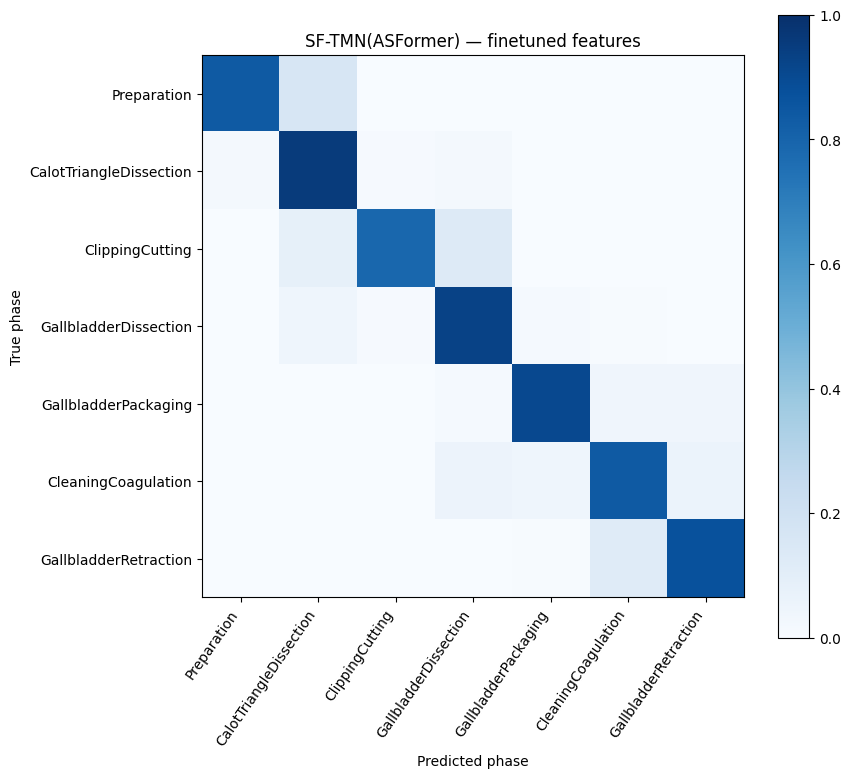


Saved archive: /kaggle/working/sftmn_asformer_finetuned_results.zip
Primary result: /kaggle/working/sftmn_asformer_finetuned/final_metrics.csv
Feature source is embedded in every output filename: finetuned


In [24]:
test_ds = FeatureSequenceDataset(TEST_IDS)
test_results, test_inference_seconds = predict_dataset(model, test_ds)
test_results = add_postprocessing(test_results)
test_metrics = evaluate_sequences(test_results, SELECTED_KEY)
per_video = per_video_metrics(test_results, SELECTED_KEY)

final_result = pd.DataFrame([{
    "model": "SF-TMN(ASFormer)",
    "feature_source": FEATURE_SOURCE,
    "feature_lineage": FEATURE_SOURCES[FEATURE_SOURCE]["description"],
    "postprocessing": SELECTED_POSTPROCESSING,
    "parameters": training_summary["parameters"],
    "training_minutes": training_summary["training_seconds"] / 60,
    "peak_vram_mb": training_summary["peak_vram_mb"],
    "validation_inference_seconds": validation_inference_seconds,
    "test_inference_seconds": test_inference_seconds,
    **test_metrics,
}])

display(final_result.T)
display(per_video)
final_result.to_csv(RESULTS_DIR / "final_metrics.csv", index=False)
per_video.to_csv(RESULTS_DIR / "test_metrics_per_video.csv", index=False)

for video_id, values in test_results.items():
    np.savez_compressed(
        PREDICTION_DIR / f"{RUN_NAME}_test_video{video_id:02d}.npz",
        labels=values["labels"],
        log_probs=values["log_probs"],
        raw=values["preds"],
        viterbi=values["viterbi"],
        selected=values[SELECTED_KEY],
    )

target = np.concatenate([test_results[v]["labels"] for v in sorted(test_results)])
prediction = np.concatenate([test_results[v][SELECTED_KEY] for v in sorted(test_results)])
matrix = confusion_matrix(target, prediction, labels=np.arange(NUM_CLASSES), normalize="true")
fig, ax = plt.subplots(figsize=(9, 8))
image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES), PHASE_NAMES, rotation=55, ha="right")
ax.set_yticks(range(NUM_CLASSES), PHASE_NAMES)
ax.set_xlabel("Predicted phase")
ax.set_ylabel("True phase")
ax.set_title(f"SF-TMN(ASFormer) — {FEATURE_SOURCE} features")
fig.colorbar(image, ax=ax)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "confusion_matrix.png", dpi=160)
plt.show()

# Published values are references, not acceptance thresholds for this different split/features.
published_reference = pd.DataFrame([
    {
        "source": "SF-TMN paper Table 5 (pooled)",
        "split": "40 train / 40 test",
        "accuracy": 0.9472,
        "edit": 0.8721,
        "f1_segmental_avg": 0.8823,
    },
    {
        "source": "SF-TMN paper Table 6 (mean per video)",
        "split": "40 train / 40 test",
        "video_mean_accuracy": 0.9543,
        "video_std_accuracy": 0.0398,
        "video_mean_precision_macro": 0.9240,
        "video_mean_recall_macro": 0.9341,
        "video_mean_jaccard_macro": 0.8614,
    },
])
published_reference.to_csv(RESULTS_DIR / "published_reference_not_comparable.csv", index=False)

protocol = {
    "implementation": "independent paper-faithful SF-TMN(ASFormer) reimplementation",
    "primary_sources": {
        "sftmn": "https://arxiv.org/abs/2306.08859",
        "asformer_code": "https://github.com/ChinaYi/ASFormer",
        "asformer_paper": "https://arxiv.org/abs/2110.08568",
    },
    "seed": SEED,
    "feature_source": FEATURE_SOURCE,
    "feature_lineage": FEATURE_SOURCES[FEATURE_SOURCE]["description"],
    "feature_directory": str(FEATURE_DIR),
    "split": {"train": TRAIN_IDS, "validation": VAL_IDS, "test": TEST_IDS},
    "model": {
        "layers_per_stage": NUM_LAYERS,
        "feature_maps": NUM_MAPS,
        "refinement_stages_per_path": NUM_REFINEMENTS,
        "segment_length": SEGMENT_LENGTH,
        "segment_pooling": "max",
        "fusion": "learned softmax-normalized scalar weights",
        "slow_refinement_input": "combined predictions and combined features",
    },
    "training": {
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
        "optimizer": "Adam",
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "batch_size_videos": 1,
        "class_weights": USE_CLASS_WEIGHTS,
        "smooth_loss_weight": SMOOTHING_WEIGHT,
        "smooth_loss_clip": SMOOTHING_CLIP,
        "amp": USE_AMP,
        "gradient_checkpointing": USE_GRADIENT_CHECKPOINTING,
    },
    "selection_rule": (
        "checkpoint and raw/Viterbi selection by validation average F1@10/25/50; "
        "test evaluated once"
    ),
    "selected_postprocessing": SELECTED_POSTPROCESSING,
    "aggregation_note": "accuracy is pooled frames; video_mean_accuracy is mean of 40 video accuracies",
}
with open(RESULTS_DIR / "protocol.json", "w") as file:
    json.dump(protocol, file, indent=2)

zip_path = Path("/kaggle/working") / f"{RUN_NAME}_results.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for path in RESULTS_DIR.rglob("*"):
        if path.is_file():
            archive.write(path, path.relative_to(RESULTS_DIR.parent))

print("\nSaved archive:", zip_path)
print("Primary result:", RESULTS_DIR / "final_metrics.csv")
print("Feature source is embedded in every output filename:", FEATURE_SOURCE)

